# EDA — 250m 생활인구 데이터 (2026-10-29)

원본 데이터를 독립적으로 점검·정리합니다. 원본 파일은 수정하지 않으며, 흡연 정답 라벨이나 다른 데이터와의 결합은 만들지 않습니다.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# VS Code/Jupyter 실행 위치와 관계없이 GitHub 저장소의 상위 data를 사용합니다.
def find_repo():
    cwd = Path.cwd().resolve()
    for p in [cwd, *cwd.parents]:
        if p.name == "do_not_lung" and (p / "notebooks").is_dir():
            return p
        candidate = p / "do_not_lung"
        if (candidate / "notebooks").is_dir():
            return candidate
    raise FileNotFoundError("do_not_lung 저장소를 찾지 못했습니다.")

REPO = find_repo()
DATA_ROOT = REPO.parent / "data"
RAW_ROOT = DATA_ROOT / "raw_data"
raw_candidates = sorted(
    (p for p in RAW_ROOT.rglob("250_LOCAL_RESD_20261029.csv") if p.is_file()),
    key=lambda p: ("사용데이터" not in p.parts, "정답데이터" not in p.parts, str(p))
)
if not raw_candidates:
    raise FileNotFoundError(f"원본 CSV 없음: {RAW_ROOT} 아래의 250_LOCAL_RESD_20261029.csv")
raw_path = raw_candidates[0]
out_dir = DATA_ROOT / "processed_data" / "local_resd_250m_20261029"
out_dir.mkdir(parents=True, exist_ok=True)

raw = pd.read_csv(raw_path, encoding="cp949", dtype=str)
print("원본 크기:", raw.shape)
display(raw.head())


원본 크기: (253803, 33)


,일자,시간,행정동코드,250M격자,생활인구합계,남자 0~9세,남자 10~14세,남자 15~19세,남자 20~24세,남자 25~29세,...,여자 25~29세,여자 30~34세,여자 35~39세,여자 40~44세,여자 45~49세,여자 50~54세,여자 55~59세,여자 60~64세,여자 65~69세,여자 70세 이상
0,20261029,00,11110515,다사52255325,4.31,*,*,*,*,*,...,*,*,*,*,*,*,*,*,*,*
1,20261029,00,11110515,다사52255350,5.35,*,*,*,*,*,...,*,*,*,*,*,*,*,*,*,*
2,20261029,00,11110515,다사52255375,11.6,*,*,*,*,*,...,*,*,*,*,*,*,*,*,*,*
3,20261029,00,11110515,다사52505325,17.11,*,*,*,*,*,...,*,*,*,*,*,*,*,*,*,*
4,20261029,00,11110515,다사52505350,884.31,*,12.53,7.46,16.15,15.76,...,25.7,59.24,51.92,32.77,50.29,43.08,31.79,35.65,49.58,91.99


In [2]:
id_cols = ["일자", "시간", "행정동코드", "250M격자"]
age_cols = [c for c in raw.columns if c.startswith("남자 ") or c.startswith("여자 ")]
clean = raw.copy()
clean["일자"] = pd.to_datetime(clean["일자"].str.strip(), format="%Y%m%d", errors="coerce")
clean["시간"] = pd.to_numeric(clean["시간"].str.strip(), errors="coerce").astype("Int64")
for c in ["행정동코드", "250M격자"]:
    clean[c] = clean[c].astype("string").str.strip()
clean["생활인구합계"] = pd.to_numeric(clean["생활인구합계"].str.replace(",", "", regex=False).str.strip(), errors="coerce")
for c in age_cols:
    s = clean[c].astype("string").str.strip()
    clean[c + "_미제공표시"] = s.eq("*").fillna(False)
    clean[c] = pd.to_numeric(s.replace("*", pd.NA), errors="coerce")

clean["일자_유효"] = clean["일자"].notna()
clean["시간_유효"] = clean["시간"].between(0, 23).fillna(False)
clean["행정동코드_형식유효"] = clean["행정동코드"].str.fullmatch(r"\\d{8}", na=False)
clean["격자코드_형식유효"] = clean["250M격자"].str.fullmatch(r"[가-힣A-Za-z0-9]+", na=False)
clean["생활인구합계_결측"] = clean["생활인구합계"].isna()

male_cols = [c for c in age_cols if c.startswith("남자 ")]
female_cols = [c for c in age_cols if c.startswith("여자 ")]
clean["남자_연령합계"] = clean[male_cols].sum(axis=1, min_count=1)
clean["여자_연령합계"] = clean[female_cols].sum(axis=1, min_count=1)
clean["연령별_인구합계"] = clean[age_cols].sum(axis=1, min_count=1)
clean["남녀_연령합계차이"] = clean["남자_연령합계"] - clean["여자_연령합계"]
clean["생활인구합계와_연령합계차이"] = clean["생활인구합계"] - clean["연령별_인구합계"]
clean["시간대구분"] = pd.cut(clean["시간"].astype(float), bins=[-1, 5, 11, 17, 23], labels=["심야", "오전", "오후", "저녁"])
clean["주야구분"] = np.where(clean["시간"].between(6, 17), "주간", np.where(clean["시간"].between(18, 23) | clean["시간"].between(0, 5), "야간", pd.NA))

print("정확 중복:", raw.duplicated().sum())
print("복합키 중복:", raw.duplicated(id_cols).sum())
print("연령별 * 표시 셀:", int(clean[[c + "_미제공표시" for c in age_cols]].to_numpy().sum()))
display(clean.describe(include="all").T.head(15))


정확 중복: 0
복합키 중복: 0
연령별 * 표시 셀: 2979562


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
일자,253803,NaN,NaN,NaN,2026-10-29 00:00:00,2026-10-29 00:00:00,2026-10-29 00:00:00,2026-10-29 00:00:00,2026-10-29 00:00:00,2026-10-29 00:00:00,NaN
시간,253803.0,<NA>,<NA>,<NA>,11.517145,0.0,6.0,12.0,18.0,23.0,6.918722
행정동코드,253803,427,11650660,3344,NaN,NaN,NaN,NaN,NaN,NaN,NaN
250M격자,253803,8567,다사57755250,96,NaN,NaN,NaN,NaN,NaN,NaN,NaN
생활인구합계,239907.0,NaN,NaN,NaN,1099.216905,4.0,45.89,531.21,1710.44,60112.23,1542.111427
남자 0~9세,67363.0,<NA>,<NA>,<NA>,12.375962,4.0,5.49,10.62,15.93,243.84,11.024535
남자 10~14세,117981.0,<NA>,<NA>,<NA>,35.104416,4.0,9.68,21.24,43.2,1018.05,46.023266
남자 15~19세,130614.0,<NA>,<NA>,<NA>,39.257006,4.0,9.86,21.15,44.5,1880.23,65.343109
남자 20~24세,142043.0,<NA>,<NA>,<NA>,41.72682,4.0,12.1,26.54,50.15,2896.15,62.616781
남자 25~29세,155902.0,<NA>,<NA>,<NA>,65.669587,4.0,17.91,43.685,82.69,2966.59,84.272638


In [3]:
clean_export = clean.copy()
clean_export["일자"] = clean_export["일자"].dt.strftime("%Y-%m-%d")
clean_export.to_csv(out_dir / "clean.csv", index=False, encoding="utf-8-sig")

hour_summary = clean.groupby("시간", dropna=False).agg(
    행수=("생활인구합계", "size"),
    생활인구합계_평균=("생활인구합계", "mean"),
    생활인구합계_중앙값=("생활인구합계", "median"),
    생활인구합계_합계=("생활인구합계", "sum")
).reset_index()
dong_summary = clean.groupby("행정동코드", dropna=False).agg(
    행수=("생활인구합계", "size"), 격자수=("250M격자", "nunique"),
    생활인구합계_평균=("생활인구합계", "mean"), 생활인구합계_합계=("생활인구합계", "sum")
).reset_index()
grid_summary = clean.groupby("250M격자", dropna=False).agg(
    행수=("생활인구합계", "size"), 행정동수=("행정동코드", "nunique"),
    생활인구합계_평균=("생활인구합계", "mean"), 생활인구합계_최대=("생활인구합계", "max")
).reset_index()
quality = pd.DataFrame([
    ["원본 행 수", len(raw)], ["원본 열 수", len(raw.columns)],
    ["정확 중복 행 수", int(raw.duplicated().sum())],
    ["복합키 중복 행 수", int(raw.duplicated(id_cols).sum())],
    ["고유 일자 수", raw["일자"].nunique()], ["고유 시간 수", raw["시간"].nunique()],
    ["고유 행정동 수", raw["행정동코드"].nunique()], ["고유 250m 격자 수", raw["250M격자"].nunique()],
    ["생활인구합계 결측 수", int(clean["생활인구합계"].isna().sum())],
    ["연령별 * 표시 셀 수", int(clean[[c + "_미제공표시" for c in age_cols]].to_numpy().sum())]
], columns=["항목", "값"])
parts = []
for group_name, frame in [("시간대별", hour_summary), ("행정동별", dong_summary), ("격자별", grid_summary)]:
    for _, row in frame.iterrows():
        parts.append({"구분": group_name, **row.to_dict()})
for _, row in quality.iterrows():
    parts.append({"구분": "품질점검", "항목": row["항목"], "값": row["값"]})
summary = pd.DataFrame(parts)
summary.to_csv(out_dir / "summary.csv", index=False, encoding="utf-8-sig")

feature_cols = id_cols + ["생활인구합계"] + age_cols + [
    "남자_연령합계", "여자_연령합계", "연령별_인구합계",
    "남녀_연령합계차이", "생활인구합계와_연령합계차이", "시간대구분", "주야구분"
]
features = clean_export[feature_cols]
features.to_csv(out_dir / "features.csv", index=False, encoding="utf-8-sig")
print("clean:", clean_export.shape, "summary:", summary.shape, "features:", features.shape)


clean: (253803, 73) summary: (9028, 13) features: (253803, 40)


C:\Users\asia\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 54217 (\N{HANGUL SYLLABLE PYEONG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\asia\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 44512 (\N{HANGUL SYLLABLE GYUN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\asia\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 49373 (\N{HANGUL SYLLABLE SAENG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\asia\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 54876 (\N{HANGUL SYLLABLE HWAL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\asia\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 5

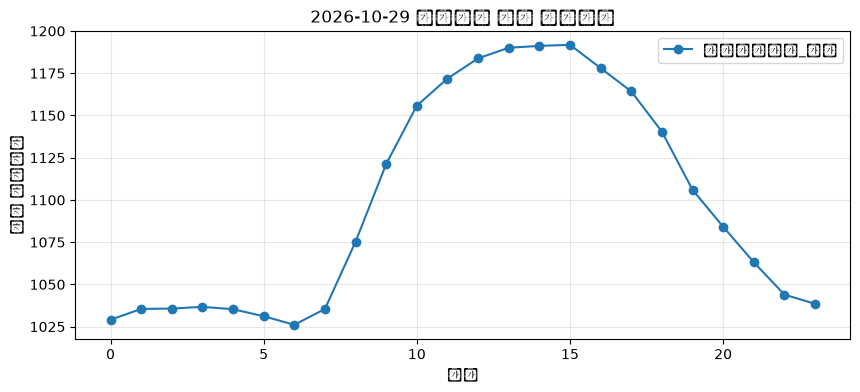

C:\Users\asia\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 54665 (\N{HANGUL SYLLABLE HAENG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\asia\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\asia\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 49373 (\N{HANGUL SYLLABLE SAENG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\asia\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 54876 (\N{HANGUL SYLLABLE HWAL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\asia\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 5106

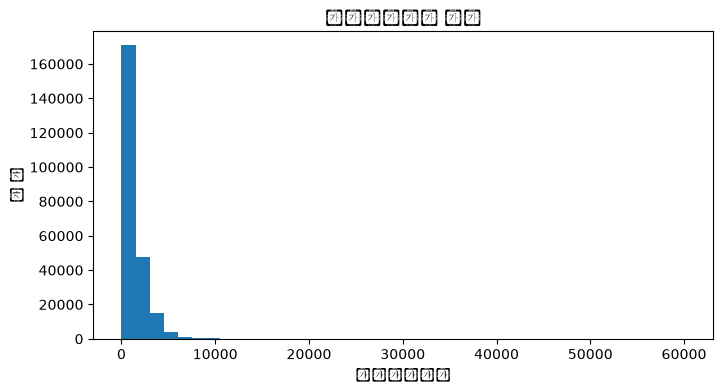

In [4]:
# 시간대별 평균 생활인구 분포
hour_summary.plot(x="시간", y="생활인구합계_평균", kind="line", marker="o", figsize=(10, 4))
plt.title("2026-10-29 시간대별 평균 생활인구")
plt.xlabel("시간"); plt.ylabel("평균 생활인구"); plt.grid(alpha=.3); plt.show()

# 생활인구 합계 분포
clean["생활인구합계"].dropna().plot(kind="hist", bins=40, figsize=(8, 4))
plt.title("생활인구합계 분포"); plt.xlabel("생활인구합계"); plt.ylabel("행 수"); plt.show()


## 해석 시 주의
- 하루 자료이므로 날짜 간 변화나 추세를 판단할 수 없습니다.
- 생활인구는 흡연 발생 또는 간접흡연 노출의 정답값이 아닙니다.
- 원본 `*` 표시는 의미를 확인할 메타데이터가 없어 0으로 바꾸지 않고 결측 및 표시 플래그로 보존합니다.
- 격자 코드는 식별자이며 좌표를 임의로 만들지 않습니다.
- 다른 데이터셋과 병합하거나 흡연 위험도·예측 라벨을 생성하지 않습니다.
